Дані

In [1]:
import os, re, glob, time
import numpy as np, pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
import xgboost as xgb
from xgboost import XGBClassifier
from sklearn.metrics import average_precision_score, roc_auc_score
from sklearn.preprocessing import QuantileTransformer
import matplotlib.pyplot as plt

os.makedirs("results/figures", exist_ok=True)
dev = torch.device("cuda")

def find(name):
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True)
    assert hits, f"не знайшов {name}: перевір Add Input"
    return hits[0]

tr = pd.read_csv(find("train_transaction.csv"))
idn = pd.read_csv(find("train_identity.csv"))
for c in tr.select_dtypes("float64").columns:
    tr[c] = tr[c].astype("float32")
df = tr.merge(idn, on="TransactionID", how="left")
df["has_identity"] = df["TransactionID"].isin(idn["TransactionID"])
df["day"] = (df["TransactionDT"] // 86400).astype(int)
df["week"] = df["day"] // 7
del tr

N = len(df)
TRAIN_W, VAL_W, TEST_W = (0, 17), (18, 21), (22, 26)
inw = lambda r: ((df.week >= r[0]) & (df.week <= r[1])).values
m_tr, m_va, m_te = inw(TRAIN_W), inw(VAL_W), inw(TEST_W)
assert (m_tr | m_va | m_te).all() and not (m_tr & m_va).any() and not (m_va & m_te).any()
assert (m_tr.sum(), m_va.sum(), m_te.sum()) == (431125, 77090, 82325)

ts, tid = df.TransactionDT.values, df.TransactionID.values
order = np.lexsort((tid, ts))
rank = np.empty(N, dtype=np.int64); rank[order] = np.arange(N)
y = df.isFraud.values
assert y.sum() == 20663
split_of = np.where(m_tr, 0, np.where(m_va, 1, 2))

X = df.drop(columns=["TransactionID", "isFraud", "TransactionDT", "day", "week"]).copy()
X["hour"] = (df.TransactionDT // 3600) % 24
X["weekday"] = (df.TransactionDT // 86400) % 7
X["has_identity"] = X["has_identity"].astype("int8")
for c in X.select_dtypes(include=["object", "category"]).columns:
    codes, _ = pd.factorize(X[c])
    X[c] = np.where(codes == -1, np.nan, codes).astype("float32")
df["D1n"] = (df["D1"] - df["TransactionDT"] / 86400).round()   # після X, у X не потрапляє

def metrics(y_true, p):
    k = int(y_true.sum()); o = np.argsort(-p)
    top1 = o[: max(1, int(0.01 * len(y_true)))]
    return {"pr_auc": average_precision_score(y_true, p),
            "roc_auc": roc_auc_score(y_true, p),
            "recall@k": y_true[o[:k]].sum() / k,
            "precision@1%": y_true[top1].mean()}

major = int(xgb.__version__.split(".")[0])
DEV = dict(tree_method="hist", device="cuda") if major >= 2 else dict(tree_method="gpu_hist")
print("готово:", X.shape)

готово: (590540, 434)


Граф і швидкі мітки сусідів із маскою відомих міток

In [2]:
def build_edges(cols, K, W_days):
    valid = df[cols].notna().all(axis=1).values
    idx = np.flatnonzero(valid); sub = df.loc[valid, cols]
    S, D = [], []
    for pos in sub.groupby(cols, sort=False).indices.values():
        if len(pos) < 2: continue
        rows = idx[pos]; rows = rows[np.argsort(rank[rows], kind="stable")]
        tt = ts[rows]; n = len(rows)
        lo = np.maximum(np.arange(n) - K, np.searchsorted(tt, tt - W_days * 86400, side="left"))
        cnt = np.arange(n) - lo; tot = int(cnt.sum())
        if tot == 0: continue
        dst_l = np.repeat(np.arange(n), cnt)
        start = np.repeat(np.cumsum(cnt) - cnt, cnt)
        src_l = np.arange(tot) - start + np.repeat(lo, cnt)
        S.append(rows[src_l].astype(np.int32)); D.append(rows[dst_l].astype(np.int32))
    return np.concatenate(S), np.concatenate(D)

DL, W_LAB = 7, 30
REL = {"u2": (["card1", "addr1"], 50, 30),
       "u3": (["card1", "addr1", "P_emaildomain"], 50, 30),
       "u5": (["card1", "addr1", "P_emaildomain", "D1n"], 50, 30)}
R_NAMES = list(REL); KMAX = {k: v[1] for k, v in REL.items()}
edges = {k: build_edges(*v) for k, v in REL.items()}
for k, (s, d) in edges.items():
    assert (rank[s] < rank[d]).all() and (s != d).all()
    assert (split_of[s[split_of[d] == 0]] == 0).all()
    print(k, f"ребер {len(s):,}")

NBR, DEG = [], []
for rn in R_NAMES:
    s, d = edges[rn]
    o = np.argsort(d, kind="stable"); ds, ss = d[o], s[o]
    cnt = np.bincount(d, minlength=N); start = np.cumsum(cnt) - cnt
    pos = np.arange(len(ds)) - start[ds]
    assert pos.max() < KMAX[rn]
    tab = np.full((N, KMAX[rn]), -1, dtype=np.int32); tab[ds, pos] = ss
    NBR.append(torch.from_numpy(tab).to(dev))
    DEG.append(torch.from_numpy(cnt.astype(np.int64)).to(dev))

# ---- попередній розрахунок меж вікон (не залежить від того, які мітки відомі) ----
BIG = 1 << 25
def precompute_rel(cols, W_days, DLd):
    valid = df[cols].notna().all(axis=1).values
    idx = np.flatnonzero(valid)
    gid = df.loc[valid, cols].groupby(cols, sort=False).ngroup().values.astype(np.int64)
    o = np.lexsort((rank[idx], gid))
    rows, g = idx[o], gid[o]
    t = ts[rows].astype(np.int64)
    key = g * BIG + t
    assert (np.diff(key) >= 0).all()
    a = np.searchsorted(key, key, side="left")
    hi = np.minimum(np.searchsorted(key, g * BIG + t - DLd * 86400, side="right"), a)
    lo = np.minimum(np.searchsorted(key, g * BIG + t - W_days * 86400, side="left"), hi)
    return rows, hi, lo

PRE = {rel: precompute_rel(cols, W_LAB, DL) for rel, (cols, _, _) in REL.items()}

def label_feats_known(rel, K):
    """мітки сусідів, відомі лише там, де K=True"""
    rows, hi, lo = PRE[rel]
    kk = np.r_[0, np.cumsum(K[rows].astype(np.int64))]
    fy = np.r_[0, np.cumsum((y * K)[rows].astype(np.int64))]
    nk = np.full(N, np.nan, "float32"); fk = np.full(N, np.nan, "float32")
    nk[rows] = kk[hi] - kk[lo]; fk[rows] = fy[hi] - fy[lo]
    return nk, fk

def check_known(K, n=40, seed=0):
    rng = np.random.default_rng(seed); bad = 0
    for rel, (cols, _, _) in REL.items():
        nk, fk = label_feats_known(rel, K)
        cand = np.flatnonzero(df[cols].notna().all(axis=1).values)
        for i in rng.choice(cand, n, replace=False):
            same = np.ones(N, bool)
            for c in cols: same &= (df[c].values == df[c].values[i])
            kn = same & K & (ts <= ts[i] - DL * 86400) & (ts >= ts[i] - W_LAB * 86400)
            if int(kn.sum()) != int(nk[i]) or int(y[kn].sum()) != int(fk[i]): bad += 1
    return bad

K_all = np.ones(N, bool)
K_rnd = np.random.default_rng(5).random(N) < 0.05
for nm, K in [("усі мітки", K_all), ("5 % міток", K_rnd)]:
    b = check_known(K); print(f"{nm}: розбіжностей з перерахунком «в лоб»: {b}"); assert b == 0
print("перевірки на витік пройдено")

u2 ребер 12,260,904
u3 ребер 5,295,877
u5 ребер 478,008
усі мітки: розбіжностей з перерахунком «в лоб»: 0
5 % міток: розбіжностей з перерахунком «в лоб»: 0
перевірки на витік пройдено


Нейромережі, тест на витік

In [3]:
Xn = X.values.astype("float32")
grp = lambda p: [i for i, c in enumerate(X.columns) if re.fullmatch(p, c)]
nanf = np.stack([np.isnan(Xn[:, g]).mean(1) for g in
                 (grp(r"V\d+"), grp(r"D\d+"), grp(r"id_\d+"), grp(r"M\d+"))], 1).astype("float32")
qt = QuantileTransformer(n_quantiles=200, output_distribution="normal",
                         subsample=200_000, random_state=0).fit(Xn[m_tr])
Xt = np.hstack([np.nan_to_num(qt.transform(Xn), nan=0.0).clip(-5, 5).astype("float32"), nanf])
XG_A = torch.from_numpy(Xt).half().to(dev)

def sample(nodes, r, s, gen=None):
    deg = DEG[r][nodes]
    u = torch.rand(nodes.shape[0], s, device=dev, generator=gen)
    idx = (u * deg.unsqueeze(1)).long().clamp_(max=KMAX[R_NAMES[r]] - 1)
    nb = NBR[r][nodes.unsqueeze(1), idx].long()
    valid = (deg > 0).unsqueeze(1).expand(-1, s) & (nb >= 0)
    return nb.clamp(min=0), valid

def hops(tgt, s1, s2, gen=None):
    B, R = tgt.shape[0], len(R_NAMES)
    n1, v1 = zip(*[sample(tgt, r, s1, gen) for r in range(R)])
    N1, M1 = torch.stack(n1, 1), torch.stack(v1, 1)
    n2, v2 = zip(*[sample(N1.reshape(-1), r, s2, gen) for r in range(R)])
    N2 = torch.stack(n2, 1).view(B, R, s1, R, s2)
    M2 = torch.stack(v2, 1).view(B, R, s1, R, s2) & M1[:, :, :, None, None]
    return N1, M1, N2, M2

class RelSAGE2(nn.Module):
    def __init__(self, F_in, H=128, R=3, drop=0.2):
        super().__init__()
        self.R = R
        self.enc = nn.Sequential(nn.Linear(F_in, H), nn.ReLU(), nn.Dropout(drop))
        self.W1s, self.W2s = nn.Linear(H, H), nn.Linear(H, H)
        self.W1n = nn.ModuleList([nn.Linear(H, H, bias=False) for _ in range(R)])
        self.W2n = nn.ModuleList([nn.Linear(H, H, bias=False) for _ in range(R)])
        self.out = nn.Sequential(nn.Dropout(drop), nn.Linear(H, 1))

    @staticmethod
    def mmean(e, m, dim):
        m = m.unsqueeze(-1).to(e.dtype)
        return (e * m).sum(dim) / m.sum(dim).clamp(min=1)

    def forward(self, XG, tgt, s1, s2, gen=None):
        B, R = tgt.shape[0], self.R
        N1, M1, N2, M2 = hops(tgt, s1, s2, gen)
        enc = lambda ids: self.enc(XG[ids].float())
        e_t = enc(tgt)
        e1 = enc(N1.reshape(-1)).view(B, R, s1, -1)
        e2 = enc(N2.reshape(-1)).view(B, R, s1, R, s2, -1)
        a2 = self.mmean(e2, M2, 4)
        h1_u = F.relu(self.W1s(e1) + sum(self.W1n[j](a2[:, :, :, j]) for j in range(R)))
        a1 = self.mmean(e1, M1, 2)
        h1_t = F.relu(self.W1s(e_t) + sum(self.W1n[j](a1[:, j]) for j in range(R)))
        ah = self.mmean(h1_u, M1, 2)
        h2 = F.relu(self.W2s(h1_t) + sum(self.W2n[j](ah[:, j]) for j in range(R)))
        return self.out(h2).squeeze(-1)

class MLPNet(nn.Module):
    def __init__(self, F_in, H=128, drop=0.2):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(F_in, H), nn.ReLU(), nn.Dropout(drop),
                                 nn.Linear(H, H), nn.ReLU(), nn.Dropout(drop), nn.Linear(H, 1))
    def forward(self, XG, tgt, s1=None, s2=None, gen=None):
        return self.net(XG[tgt].float()).squeeze(-1)

sp_t = torch.as_tensor(split_of, device=dev); t_t = torch.as_tensor(ts, device=dev)
rg = np.random.default_rng(0)
for sp, cap in [(0, 0), (1, 1)]:
    ids = torch.as_tensor(rg.choice(np.flatnonzero(split_of == sp), 4000, replace=False), device=dev)
    N1, M1, N2, M2 = hops(ids, 10, 5)
    assert (sp_t[N1[M1]] <= cap).all() and (sp_t[N2[M2]] <= cap).all(), "сусіди з майбутньої частини"
    assert (t_t[N1] <= t_t[ids][:, None, None])[M1].all(), "сусід пізніший за вузол (крок 1)"
    assert (t_t[N2] <= t_t[N1][:, :, :, None, None])[M2].all(), "сусід пізніший за вузол (крок 2)"
print("тест на витік пройдено")

тест на витік пройдено


Функції експерименту і пробний запуск

In [4]:
@torch.no_grad()
def predict_avg(model, XG, idx_np, s1, s2, seed, bs=2048):
    model.eval(); ids = torch.as_tensor(idx_np, device=dev)
    gen = torch.Generator(device=dev); gen.manual_seed(1234 + 100 * seed)
    return torch.cat([torch.sigmoid(model(XG, ids[i:i + bs], s1, s2, gen)).float().cpu()
                      for i in range(0, len(ids), bs)]).numpy()

def train_nn(make_model, XG, tr_idx, va_idx, spw_l, seed, epochs, patience, bs, s1=10, s2=5, lr=1e-3):
    torch.manual_seed(seed); np.random.seed(seed)
    model = make_model(XG.shape[1]).to(dev)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=1e-5)
    posw = torch.tensor(float(spw_l), device=dev)
    tri = torch.as_tensor(tr_idx, device=dev)
    yt = torch.as_tensor(y, device=dev).float()
    best, bad, state, ep_best = -1.0, 0, None, 0
    for ep in range(1, epochs + 1):
        model.train()
        perm = tri[torch.randperm(len(tri), device=dev)]
        for i in range(0, len(perm), bs):
            b = perm[i:i + bs]
            loss = F.binary_cross_entropy_with_logits(model(XG, b, s1, s2), yt[b], pos_weight=posw)
            opt.zero_grad(); loss.backward(); opt.step()
        v = average_precision_score(y[va_idx], predict_avg(model, XG, va_idx, s1, s2, seed))
        if v > best:
            best, bad, ep_best = v, 0, ep
            state = {k: t.detach().clone() for k, t in model.state_dict().items()}
        else:
            bad += 1
            if bad >= patience: break
    model.load_state_dict(state)
    r = metrics(y[m_te], predict_avg(model, XG, np.flatnonzero(m_te), s1, s2, seed))
    r.update(best_epoch=ep_best, val_aucpr=best)
    return r

def fit_xgb_l(Xf, tr_idx, va_idx, spw_l, seed):
    m = XGBClassifier(n_estimators=1000, learning_rate=0.1, max_depth=6, subsample=0.8,
                      colsample_bytree=0.8, scale_pos_weight=spw_l, eval_metric="aucpr",
                      early_stopping_rounds=50, random_state=seed, **DEV)
    m.fit(Xf.iloc[tr_idx], y[tr_idx], eval_set=[(Xf.iloc[va_idx], y[va_idx])], verbose=False)
    r = metrics(y[m_te], m.predict_proba(Xf[m_te])[:, 1])
    r.update(best_epoch=m.best_iteration, val_aucpr=m.best_score)
    return r

CFG = {0.01: dict(epochs=80, patience=12, bs=256),
       0.05: dict(epochs=50, patience=10, bs=512),
       0.20: dict(epochs=30, patience=6,  bs=1024)}

def run_exp(scen, p, seed):
    rng = np.random.default_rng(seed * 1000 + int(round(p * 1000)))
    K = rng.random(N) < p                                  # які мітки відомі системі
    tr_l, va_l = np.flatnonzero(m_tr & K), np.flatnonzero(m_va & K)
    assert y[tr_l].sum() > 20 and y[va_l].sum() >= 5
    spw_l = (y[tr_l] == 0).sum() / (y[tr_l] == 1).sum()
    if scen == "S2":
        LFm = {}
        for rel in R_NAMES:
            nk, fk = label_feats_known(rel, K)
            LFm[f"{rel}_nk"], LFm[f"{rel}_fk"] = nk, fk
            LFm[f"{rel}_rate"] = (fk / np.where(nk > 0, nk, np.nan)).astype("float32")
        LFm = pd.DataFrame(LFm); Xx = pd.concat([X, LFm], axis=1)
        cols_ = []
        for r in R_NAMES:
            g = lambda k, r=r: np.nan_to_num(LFm[f"{r}_{k}"].values)
            cols_ += [np.log1p(g("nk")), np.log1p(g("fk")), g("rate"), (g("nk") > 0).astype("float32")]
        M = np.stack(cols_, 1).astype("float32")
        M = (M - M[m_tr].mean(0)) / (M[m_tr].std(0) + 1e-6)
        XG = torch.from_numpy(np.hstack([Xt, M])).half().to(dev)
    else:
        Xx, XG = X, XG_A
    out = []
    for model, fn in [("XGBoost", lambda: fit_xgb_l(Xx, tr_l, va_l, spw_l, seed)),
                      ("MLP", lambda: train_nn(MLPNet, XG, tr_l, va_l, spw_l, seed, **CFG[p])),
                      ("GNN", lambda: train_nn(RelSAGE2, XG, tr_l, va_l, spw_l, seed, **CFG[p]))]:
        t0 = time.time(); r = fn()
        r.update(scenario=scen, p=p, seed=seed, model=model, n_train=len(tr_l),
                 n_fraud_train=int(y[tr_l].sum()), secs=time.time() - t0)
        out.append(r)
    return out

# ---- пробний запуск: 5 % міток, seed 0 ----
pilot = []
for scen in ("S1", "S2"):
    t0 = time.time(); rs = run_exp(scen, 0.05, 0); pilot += rs
    print(scen, f"({time.time()-t0:.0f} с)", {r["model"]: round(float(r["pr_auc"]), 4) for r in rs},
          "| розмічених у train:", rs[0]["n_train"], "фроду:", rs[0]["n_fraud_train"], flush=True)
pd.DataFrame(pilot).to_csv("results/ieee_cis_low_labels_pilot.csv", index=False)

/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [15:38:29] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


S1 (39 с) {'XGBoost': 0.4449, 'MLP': 0.3834, 'GNN': 0.4047} | розмічених у train: 21620 фроду: 806
S2 (39 с) {'XGBoost': 0.4455, 'MLP': 0.4099, 'GNN': 0.4282} | розмічених у train: 21620 фроду: 806


Повний запуск, 5 seed (≈ 60-80 хв)

In [5]:
rows = []
for sd in range(5):
    for p in (0.01, 0.05, 0.20):
        for scen in ("S1", "S2"):
            t0 = time.time(); rows += run_exp(scen, p, sd)
            print(f"seed {sd} p={p} {scen}: {time.time()-t0:.0f} с", flush=True)
    pd.DataFrame(rows).to_csv("results/ieee_cis_low_labels_5seeds.csv", index=False)   # зберігаємо після кожного seed

seed 0 p=0.01 S1: 18 с
seed 0 p=0.01 S2: 16 с
seed 0 p=0.05 S1: 37 с
seed 0 p=0.05 S2: 40 с
seed 0 p=0.2 S1: 105 с
seed 0 p=0.2 S2: 104 с
seed 1 p=0.01 S1: 13 с
seed 1 p=0.01 S2: 16 с
seed 1 p=0.05 S1: 48 с
seed 1 p=0.05 S2: 48 с
seed 1 p=0.2 S1: 100 с
seed 1 p=0.2 S2: 136 с
seed 2 p=0.01 S1: 13 с
seed 2 p=0.01 S2: 18 с
seed 2 p=0.05 S1: 40 с
seed 2 p=0.05 S2: 34 с
seed 2 p=0.2 S1: 93 с
seed 2 p=0.2 S2: 122 с
seed 3 p=0.01 S1: 12 с
seed 3 p=0.01 S2: 14 с
seed 3 p=0.05 S1: 36 с
seed 3 p=0.05 S2: 39 с
seed 3 p=0.2 S1: 99 с
seed 3 p=0.2 S2: 149 с
seed 4 p=0.01 S1: 12 с
seed 4 p=0.01 S2: 14 с
seed 4 p=0.05 S1: 42 с
seed 4 p=0.05 S2: 37 с
seed 4 p=0.2 S1: 112 с
seed 4 p=0.2 S2: 104 с


Підсумок і один рисунок

mean                   std               
model            GNN    MLP XGBoost    GNN    MLP XGBoost
scenario p                                               
S1       0.01  0.335  0.347   0.367  0.020  0.015   0.021
         0.05  0.366  0.400   0.425  0.074  0.014   0.039
         0.20  0.429  0.428   0.477  0.011  0.008   0.004
S2       0.01  0.333  0.318   0.358  0.019  0.028   0.014
         0.05  0.433  0.417   0.440  0.013  0.019   0.014
         0.20  0.517  0.512   0.546  0.008  0.010   0.006

,сценарій,p,GNN−MLP,std,XGBoost−MLP,"умова виявлена (GNN−MLP > 0,01)"
0,S1,0.01,-0.0121,0.0065,0.0208,False
1,S1,0.05,-0.0334,0.0744,0.0257,False
2,S1,0.20,0.0008,0.0067,0.0484,False
3,S2,0.01,0.0149,0.0196,0.0396,True
4,S2,0.05,0.0153,0.0165,0.0222,True
5,S2,0.20,0.0049,0.0067,0.0338,False


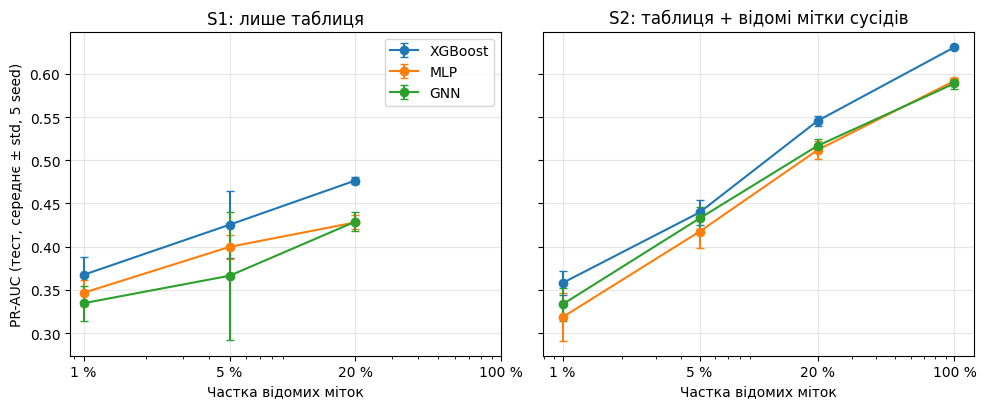

In [6]:
R = pd.DataFrame(rows)
tab = R.groupby(["scenario", "p", "model"])["pr_auc"].agg(["mean", "std"]).round(3).unstack("model")
display(tab)

out = []
for (scen, p), g in R.groupby(["scenario", "p"]):
    pv = g.pivot(index="seed", columns="model", values="pr_auc")
    d_gm, d_xm = pv["GNN"] - pv["MLP"], pv["XGBoost"] - pv["MLP"]
    out.append({"сценарій": scen, "p": p, "GNN−MLP": d_gm.mean(), "std": d_gm.std(),
                "XGBoost−MLP": d_xm.mean(), "умова виявлена (GNN−MLP > 0,01)": d_gm.mean() > 0.01})
diff = pd.DataFrame(out).round(4); display(diff)
diff.to_csv("results/ieee_cis_low_labels_diff.csv", index=False)

ref = {"XGBoost": (0.631, 0.001), "MLP": (0.592, 0.003), "GNN": (0.589, 0.006)}  # S2, p=100 % (ноутбук 13)
fig, ax = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
for a, scen, title in [(ax[0], "S1", "S1: лише таблиця"), (ax[1], "S2", "S2: таблиця + відомі мітки сусідів")]:
    for model in ("XGBoost", "MLP", "GNN"):
        g = R[(R.scenario == scen) & (R.model == model)].groupby("p")["pr_auc"].agg(["mean", "std"])
        xs, ms, ss = list(g.index), list(g["mean"]), list(g["std"])
        if scen == "S2": xs.append(1.0); ms.append(ref[model][0]); ss.append(ref[model][1])
        a.errorbar(xs, ms, yerr=ss, marker="o", capsize=3, label=model)
    a.set_xscale("log"); a.set_xticks([0.01, 0.05, 0.2, 1.0]); a.set_xticklabels(["1 %", "5 %", "20 %", "100 %"])
    a.set_title(title); a.set_xlabel("Частка відомих міток"); a.grid(alpha=0.3)
ax[0].set_ylabel("PR-AUC (тест, середнє ± std, 5 seed)"); ax[0].legend()
plt.tight_layout(); plt.savefig("results/figures/ieee_cis_low_labels.png", dpi=200); plt.show()

Діагностика

In [7]:
from scipy import stats
R = pd.DataFrame(rows)
rt = []
for (scen, p), g in R.groupby(["scenario", "p"]):
    pv = g.pivot(index="seed", columns="model", values="pr_auc")
    d = pv["GNN"] - pv["MLP"]; t, pval = stats.ttest_1samp(d, 0.0)
    rt.append({"сценарій": scen, "p": p, "GNN−MLP": d.mean(), "SE": d.std() / np.sqrt(len(d)),
               "t": t, "p-value": pval})
display(pd.DataFrame(rt).round(4))
print(R[(R.scenario == "S1") & (R.p == 0.05)].pivot(index="seed", columns="model", values="pr_auc").round(3))
print(R[(R.scenario == "S1") & (R.p == 0.05) & (R.model == "GNN")][["seed", "best_epoch", "val_aucpr", "pr_auc"]].round(3))

,сценарій,p,GNN−MLP,SE,t,p-value
0,S1,0.01,-0.0121,0.0029,-4.1483,0.0143
1,S1,0.05,-0.0334,0.0333,-1.0035,0.3724
2,S1,0.20,0.0008,0.0030,0.2795,0.7938
3,S2,0.01,0.0149,0.0088,1.7032,0.1637
4,S2,0.05,0.0153,0.0074,2.0730,0.1069
5,S2,0.20,0.0049,0.0030,1.6433,0.1757


model    GNN    MLP  XGBoost
seed                        
0      0.405  0.383    0.445
1      0.234  0.398    0.443
2      0.389  0.396    0.356
3      0.401  0.399    0.445
4      0.403  0.422    0.439
    seed  best_epoch  val_aucpr  pr_auc
8      0           7      0.337   0.405
26     1          16      0.429   0.234
44     2          11      0.384   0.389
62     3           8      0.307   0.401
80     4          12      0.350   0.403


Реплікація

In [8]:
rep = []
for sd in range(5, 15):
    for p in (0.01, 0.05):
        t0 = time.time(); rep += run_exp("S2", p, sd)
        print(f"seed {sd} p={p} S2: {time.time()-t0:.0f} с", flush=True)
    pd.DataFrame(rep).to_csv("results/ieee_cis_low_labels_replication_S2.csv", index=False)
RP = pd.DataFrame(rep); out = []
for p, g in RP.groupby("p"):
    pv = g.pivot(index="seed", columns="model", values="pr_auc")
    d = pv["GNN"] - pv["MLP"]; t, pval = stats.ttest_1samp(d, 0.0)
    out.append({"p": p, "seed": len(d), "GNN−MLP": d.mean(), "SE": d.std() / np.sqrt(len(d)),
                "t": t, "p-value": pval, "XGBoost−GNN": (pv["XGBoost"] - pv["GNN"]).mean(),
                "підтверджено (>0,01 і p<0,025)": bool(d.mean() > 0.01 and pval < 0.025)})
rep_tab = pd.DataFrame(out).round(4); display(rep_tab)
rep_tab.to_csv("results/ieee_cis_low_labels_replication_summary.csv", index=False)

seed 5 p=0.01 S2: 12 с
seed 5 p=0.05 S2: 35 с
seed 6 p=0.01 S2: 16 с
seed 6 p=0.05 S2: 61 с
seed 7 p=0.01 S2: 13 с
seed 7 p=0.05 S2: 43 с
seed 8 p=0.01 S2: 17 с
seed 8 p=0.05 S2: 45 с
seed 9 p=0.01 S2: 19 с
seed 9 p=0.05 S2: 46 с
seed 10 p=0.01 S2: 16 с
seed 10 p=0.05 S2: 40 с
seed 11 p=0.01 S2: 18 с
seed 11 p=0.05 S2: 45 с
seed 12 p=0.01 S2: 15 с
seed 12 p=0.05 S2: 38 с
seed 13 p=0.01 S2: 14 с
seed 13 p=0.05 S2: 41 с
seed 14 p=0.01 S2: 15 с
seed 14 p=0.05 S2: 38 с


,p,seed,GNN−MLP,SE,t,p-value,XGBoost−GNN,"підтверджено (>0,01 і p<0,025)"
0,0.01,10,0.0042,0.0111,0.3740,0.7170,0.0187,False
1,0.05,10,-0.0014,0.0055,-0.2552,0.8043,0.0140,False
